In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.style.use("ggplot")


### Lectura del dataset

In [2]:
df = pd.read_csv("../../data/raw/dataset_practica_final.csv")


In [3]:
# Primeras filas de datos
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
# Dimension del dataframe
df.shape

(119390, 32)

In [5]:
# Informacion del dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [6]:
# Descripción estadística de todas las columnas
df.describe(include="all").transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


### Analisis de valores nulos

Identificaremos las variables que contienen valores nulos
y calcularemos su porcentaje respecto al total de registros.

In [7]:
missing = df.isna().sum().sort_values(ascending=False)

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_df = pd.DataFrame({"nulos": missing, "porcentaje": missing_pct})

missing_df = missing_df[missing_df["nulos"] > 0]

missing_df

,nulos,porcentaje
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


### Interpretacion

Se observan valores nulos en `company`, `agent`, `country` y `children`.
`company` es la variable con más ausencias, seguida de `agent`.
Ambas columnas deberán tratarse con cuidado antes del modelado.

In [8]:
# Duplicados
duplicados = df.duplicated().sum()
duplicados

np.int64(31994)

In [9]:
df[df.duplicated()].head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


Existen registros duplicados en el dataset.
Antes de eliminarlos, conviene revisar si representan reservas realmente repetidas o si son duplicados puros del fichero.

In [10]:
# Variable Objetivo
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [11]:
# Variable objetivo en porcentajes
target_pct = df["is_canceled"].value_counts(normalize=True) * 100
target_pct

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

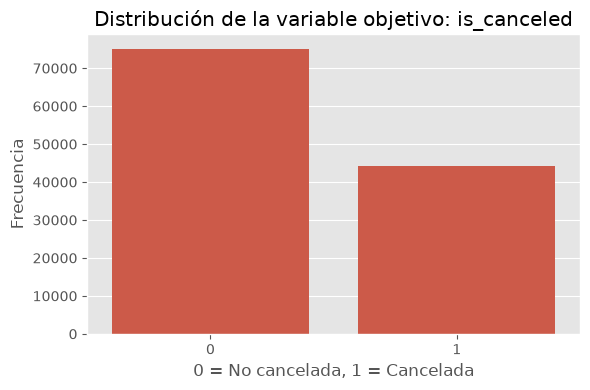

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_canceled")
plt.title("Distribución de la variable objetivo: is_canceled")
plt.xlabel("0 = No cancelada, 1 = Cancelada")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

La variable objetivo está algo desbalanceada, con más reservas no canceladas que canceladas.

## Análisis de variables numéricas

Analisis de la distribución de las variables
numéricas para conocer sus rangos, tendencias y posibles
valores atípicos.

In [13]:
numeric_cols = df.select_dtypes(include="number").columns

numeric_cols

Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='str')

In [14]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


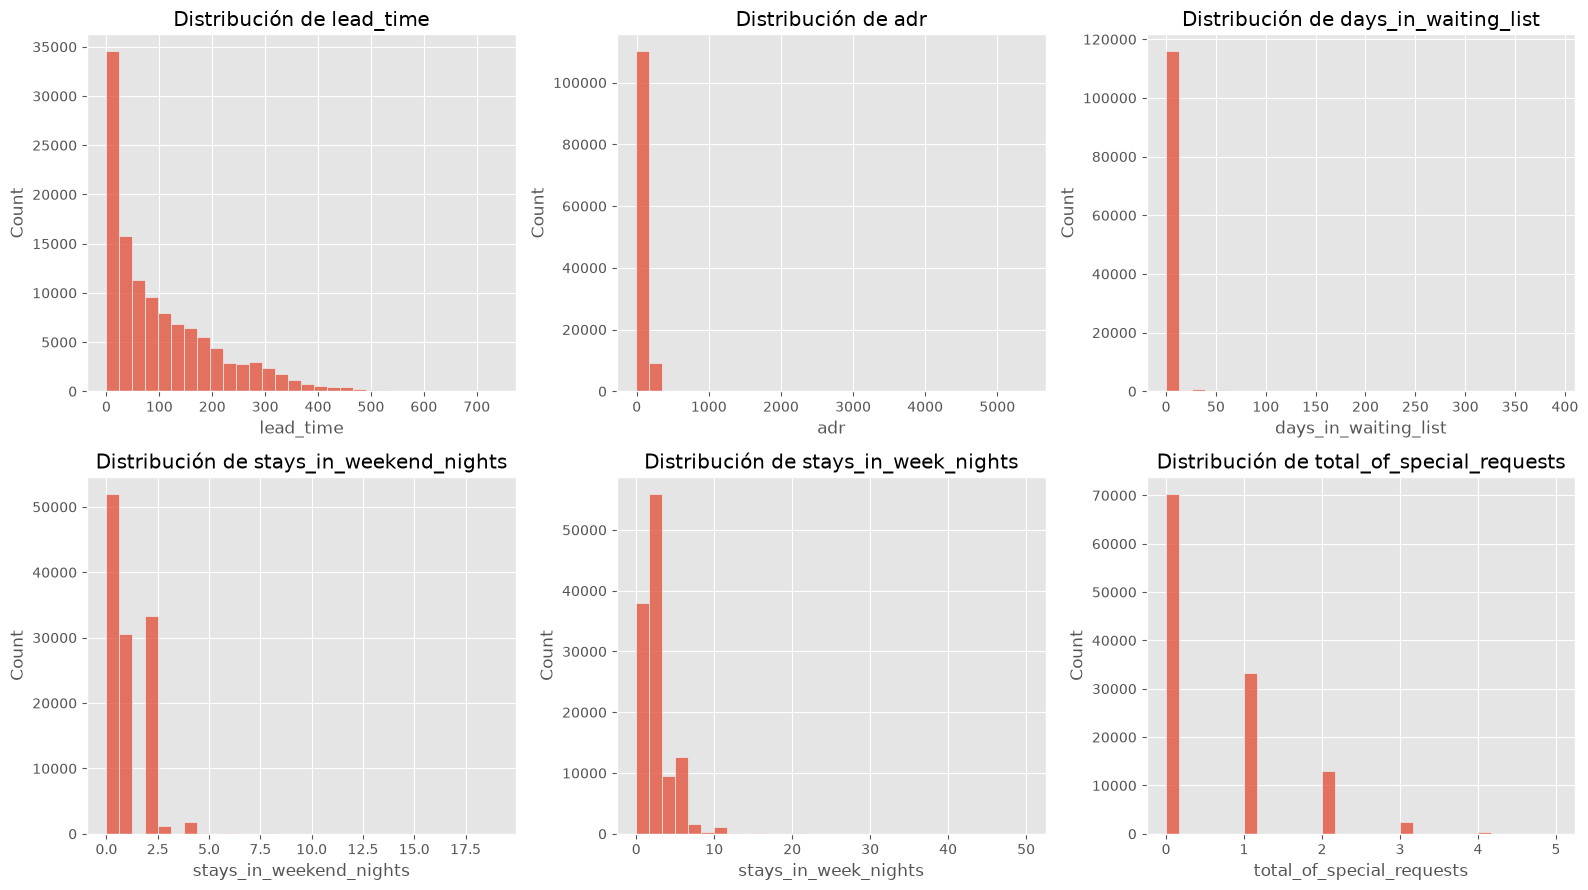

In [15]:
# Distribucion de variables numericas
numeric_to_plot = [
    "lead_time",
    "adr",
    "days_in_waiting_list",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_of_special_requests",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for column, ax in zip(numeric_to_plot, axes.flat):
    sns.histplot(data=df, x=column, bins=30, ax=ax)

    ax.set_title(f"Distribución de {column}")

plt.tight_layout()
plt.show()

### Detección de valores atípicos (Outliers)

Utilizaremos diagramas de caja para identificar valores que
se encuentran alejados de la distribución habitual de las
variables numéricas.

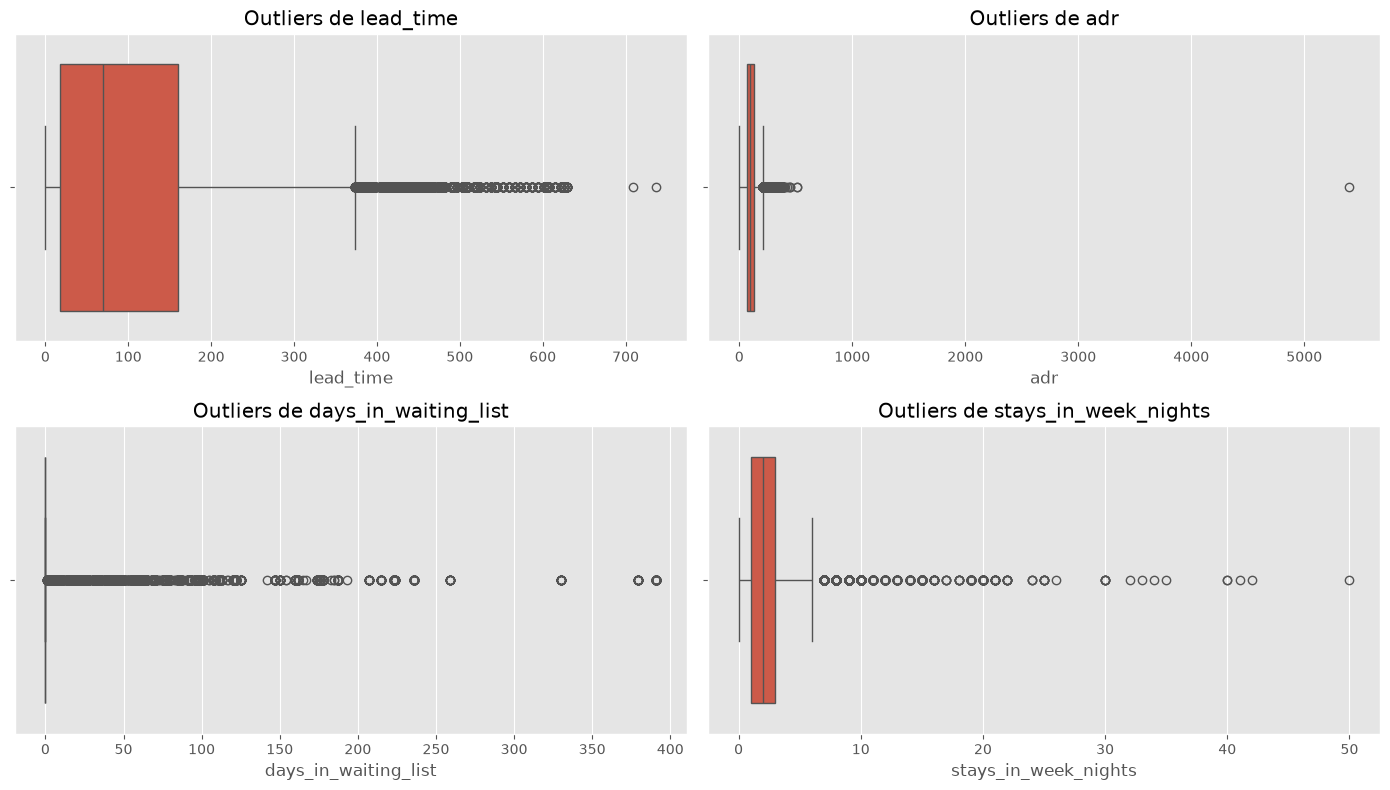

In [16]:
outlier_cols = [
    "lead_time",
    "adr",
    "days_in_waiting_list",
    "stays_in_week_nights",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for column, ax in zip(outlier_cols, axes.flat):
    sns.boxplot(data=df, x=column, ax=ax, showfliers=True)

    ax.set_title(f"Outliers de {column}")

plt.tight_layout()
plt.show()

## Analisis variables categoricas


In [17]:
# Identificar las variables categoricas

categorical_cols = df.select_dtypes(include=["object", "category"]).columns
categorical_cols

C:\Users\jorpa\AppData\Local\Temp\ipykernel_34068\2931960437.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns


Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status',
       'reservation_status_date'],
      dtype='str')

In [18]:
# Numero de categorias diferentes
df[categorical_cols].nunique().sort_values(ascending=False)

reservation_status_date    926
country                    177
assigned_room_type          12
arrival_date_month          12
reserved_room_type          10
market_segment               8
distribution_channel         5
meal                         5
customer_type                4
deposit_type                 3
reservation_status           3
hotel                        2
dtype: int64

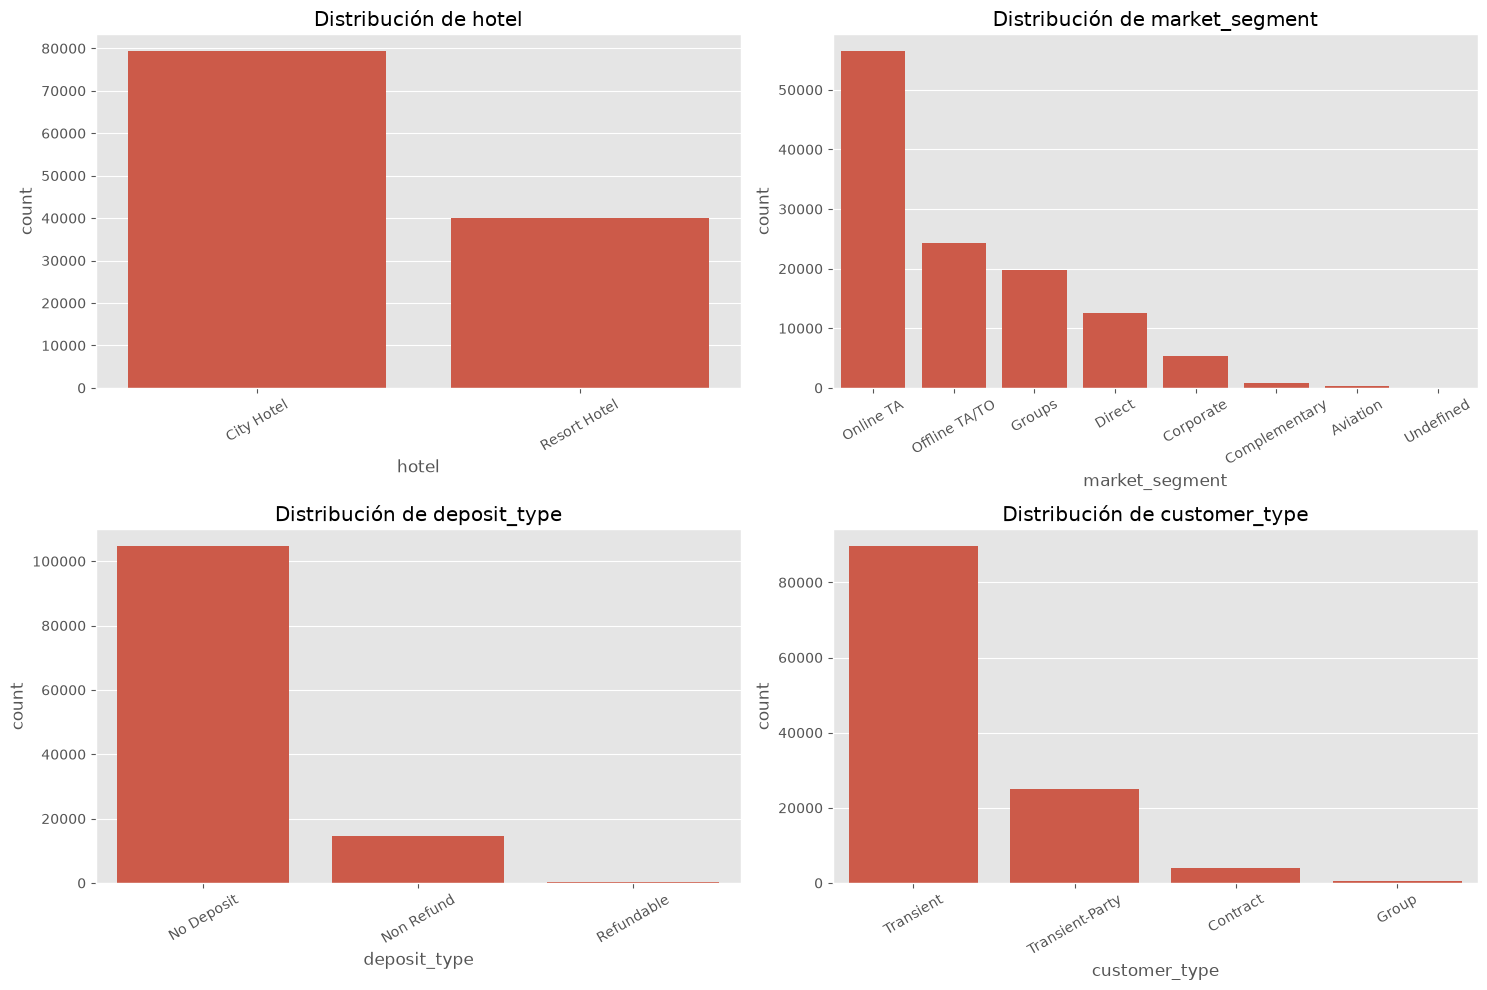

In [19]:
# Distribucion de las variables categoricas

categorical_to_plot = [
    "hotel",
    "market_segment",
    "deposit_type",
    "customer_type",
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, ax in zip(categorical_to_plot, axes.flat):
    sns.countplot(
        data=df, x=column, order=df[column].value_counts().index, ax=ax
    )

    ax.set_title(f"Distribución de {column}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


Se seleccionaron variables categóricas con interés de negocio y baja o media cardinalidad, para facilitar la interpretación visual y analizar su relación con la variable objetivo is_canceled.

hotel:
Es una de las variables más fáciles de interpretar: compara el comportamiento entre City Hotel y Resort Hotel.

market_segment:
Te dice por qué canal llegó la reserva. Suele estar muy relacionado con el tipo de cliente y con el riesgo de cancelación.

deposit_type:
Es muy relevante porque refleja el compromiso del cliente con la reserva. Suele ser una variable con bastante poder explicativo.

customer_type:
Ayuda a distinguir si la reserva viene de un cliente transitorio, contrato, grupo, etc. Ese perfil suele cambiar mucho el comportamiento de cancelación.

## Relación entre variables y cancelaciones

Objetivo: predecir si una reserva será cancelada.

Por tanto, debemos estudiar qué relación existe entre las variables predictoras y is_canceled.

### Variables numéricas frente a cancelaciones

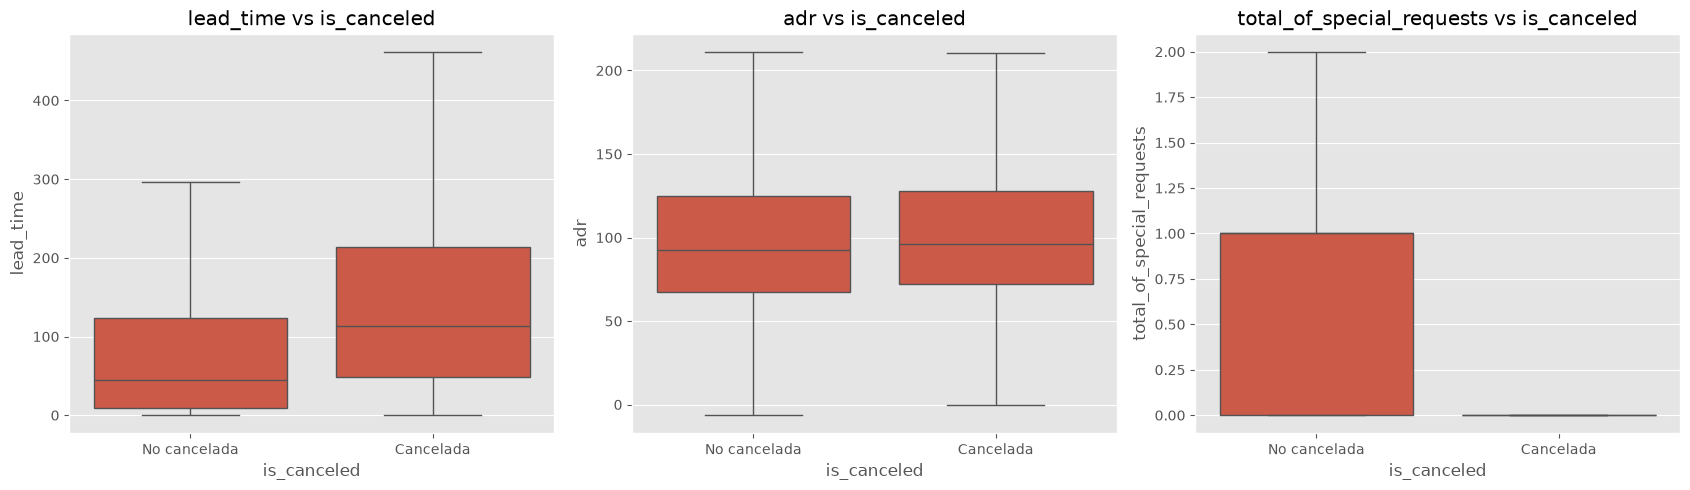

In [20]:
numeric_target_cols = ["lead_time", "adr", "total_of_special_requests"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for column, ax in zip(numeric_target_cols, axes):
    sns.boxplot(data=df, x="is_canceled", y=column, ax=ax, showfliers=False)

    ax.set_title(f"{column} vs is_canceled")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No cancelada", "Cancelada"])

plt.tight_layout()
plt.show()

### Variables categóricas frente a cancelaciones

In [21]:
# Calculo del porcentaje de cancelaciones por tipo de hotel.

cancellation_by_hotel = df.groupby("hotel")["is_canceled"].mean() * 100

cancellation_by_hotel

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64

En este dataset, el City Hotel presenta aproximadamente un 41,73 % de cancelaciones y el Resort Hotel un 27,76 %.

In [22]:
# Otras comparaciones
# Analisa distintas variables tomando las que tienen mayores cancelaciones,
# mostrandolas de forma ascendente y que por lo menos tengan
# mas de 100 registros.

categorical_target_cols = [
    "hotel",
    "market_segment",
    "deposit_type",
    "customer_type",
]

for column in categorical_target_cols:
    cancellation_rate = (
        df.groupby(column)["is_canceled"].agg(["count", "mean"]).reset_index()
    )

    cancellation_rate["mean"] *= 100

    cancellation_rate = cancellation_rate[cancellation_rate["count"] >= 100]

    cancellation_rate = cancellation_rate.sort_values(
        by="mean", ascending=False
    )

    print(cancellation_rate)
    print()

          hotel  count       mean
0    City Hotel  79330  41.726963
1  Resort Hotel  40060  27.763355

  market_segment  count       mean
4         Groups  19811  61.062036
6      Online TA  56477  36.721143
5  Offline TA/TO  24219  34.316033
0       Aviation    237  21.940928
2      Corporate   5295  18.734655
3         Direct  12606  15.341901
1  Complementary    743  13.055182

  deposit_type   count       mean
1   Non Refund   14587  99.362446
0   No Deposit  104641  28.377022
2   Refundable     162  22.222222

     customer_type  count       mean
2        Transient  89613  40.746320
0         Contract   4076  30.961727
3  Transient-Party  25124  25.429868
1            Group    577  10.225303



### Posible fuga de información: `assigned_room_type`

`reserved_room_type` es la habitación que se pide al hacer la reserva,
mientras que `assigned_room_type` es la habitación que el hotel asigna
finalmente. Esa asignación sucede después de la reserva, normalmente
cuando el cliente llega, por lo que puede haber una fuga de información
temporal.

Compararemos ambas variables para ver cómo cambian las cancelaciones
cuando la habitación asignada es distinta de la reservada.

In [23]:
# Comparamos la habitacion reservada con la asignada
# y calculamos el porcentaje de cancelaciones en cada caso.

room_changed = (df["assigned_room_type"] != df["reserved_room_type"]).rename(
    "room_changed"
)

room_change_rate = (
    df.groupby(room_changed)["is_canceled"]
    .agg(["count", "mean"])
    .reset_index()
)

room_change_rate["mean"] *= 100

room_change_rate

,room_changed,count,mean
0,False,104473,41.562892
1,True,14917,5.376416


### Interpretación

En el 12,49 % de las reservas la habitación asignada es distinta
de la reservada. En esos casos solo se cancela un 5,38 %,
frente al 41,56 % cuando ambas coinciden.

Tiene sentido, porque la habitación solo se cambia a quien llega al hotel,
y quien llega no ha cancelado. Como esa información no se conoce en el
momento de la reserva, `assigned_room_type` se excluirá de los predictores
para evitar Data Leakage.

### Conclusiones del análisis exploratorio (EDA)

Tras realizar el análisis exploratorio del dataset, se han identificado
diversas características que permiten comprender mejor el comportamiento
de las reservas hoteleras y su relación con las cancelaciones.

### 1. Calidad y estructura de los datos

El conjunto de datos original contiene 119.390 registros y 32 variables.

Se han detectado valores ausentes en cuatro variables:

- `company`: 94,31 % de valores nulos.
- `agent`: 13,69 % de valores nulos.
- `country`: 0,41 % de valores nulos.
- `children`: 4 registros sin información.

También se han identificado 31.994 filas duplicadas respecto a una
aparición anterior. Será necesario evaluar su eliminación antes del
entrenamiento para evitar que registros idénticos puedan aparecer
simultáneamente en los conjuntos de entrenamiento y prueba.

### 2. Distribución de la variable objetivo

La variable `is_canceled` presenta la siguiente distribución:

- Reservas no canceladas (0): 62,96 %.
- Reservas canceladas (1): 37,04 %.

Existe cierto desequilibrio entre ambas clases, aunque no es extremo.
Por ello, durante la evaluación de los modelos no utilizaremos
únicamente Accuracy, sino que también consideraremos Precision,
Recall, F1-score y ROC-AUC.

### 3. Análisis de variables numéricas

Se han observado distribuciones asimétricas y posibles valores atípicos
en algunas variables.

Destaca especialmente `lead_time`, cuyo valor máximo alcanza los
737 días. Además, las reservas canceladas presentan una mediana de
113 días de antelación, frente a 45 días en las reservas no canceladas.

En la variable `adr` (precio promedio por noche) se ha detectado un valor
extremo de 5.400 y también un valor negativo de -6,38. Estos registros
deberán investigarse y tratarse durante el preprocesamiento.

Por otra parte, `total_of_special_requests` presenta una mediana de
una solicitud en las reservas no canceladas y de cero en las canceladas.
Esto sugiere que puede aportar información útil para la predicción.

### 4. Análisis de variables categóricas

Se han observado diferencias en las tasas de cancelación según
determinadas características de las reservas:

- Tipo de hotel: City Hotel presenta aproximadamente un 41,73 %
  de cancelaciones, frente al 27,76 % de Resort Hotel.
- Tipo de depósito: las reservas Non Refund presentan una tasa
  de cancelación del 99,36 %.
- Segmento de mercado: el segmento Groups presenta una tasa
  de cancelación aproximada del 61,06 %.
- Tipo de cliente: los clientes Transient presentan una tasa
  de cancelación del 40,75 %.

Estas diferencias muestran que las variables categóricas pueden
aportar información relevante al modelo.

### 5. Decisiones para el preprocesamiento

A partir de los resultados obtenidos, se plantean las siguientes
decisiones:

- Revisar y eliminar los duplicados exactos.
- Analizar las variables `agent` y `company`, considerando su elevado
  número de valores ausentes y su naturaleza identificativa.
- Imputar los valores ausentes de `children` y `country`.
- Investigar y tratar los valores extremos de `adr`.
- Codificar las variables categóricas mediante técnicas como OneHotEncoder.
- Escalar las variables numéricas para aquellos modelos que lo requieran.
- Excluir `reservation_status`, `reservation_status_date` y
  `assigned_room_type` del conjunto de predictores para evitar
  Data Leakage.

### 6. Conclusión general

El análisis exploratorio confirma que el dataset contiene información
relevante para abordar el problema de predicción de cancelaciones
hoteleras mediante técnicas de Machine Learning.

Variables como `lead_time`, `deposit_type`, `hotel`,
`market_segment` y `total_of_special_requests` muestran patrones
interesantes que justifican su estudio durante el entrenamiento.

El siguiente paso será realizar un preprocesamiento estructurado
que permita limpiar y transformar los datos, preparando un conjunto
de características adecuado para entrenar y comparar los diferentes
algoritmos de clasificación binaria.